# QUEM VAI BEM EM LINGUAGENS TAMBÉM VAI BEM EM REDAÇÃO?

## Hipótese

É de se esperar que exista uma relação direta entre as notas de linguagens e códigos (LC) e as notas de redação. Além de serem duas áreas intimamente ligadas, existe dentro das competências de redação um parâmetro exclusivamente destinado ao domínio da escrita formal. Apesar da prova de LC não avaliar apenas língua portuguesa, dentro da matriz de referência existem habilidades que são úteis também à redação. O objetivo dessa etapa é investigar se há de fato relação entre as notas de LC e redação.

## Metodologia e engenharia

Criamos uma tabela mart contendo apenas as notas de LC e redação de cada estudante. Para manter a integridade da tabela, descartamos situações em que apenas uma das notas citadas está presente. As duas colunas vêm diretamente da tabela de respostas dos inscritos.

Dividimos então as notas da redação em faixas com intervalo de 20 pontos, pois esse é o avanço mínimo que se pode ter. Para cada uma dessas faixas, calculamos a média das notas de LC dos alunos que obtiveram aquela nota em redação. Assim, é possível acompanharmos a evolução das notas da redação e as correspondentes notas de LC.

A tabela mart no banco de dados já está ordenada por nota da redação.

## Importação dos dados

In [18]:
import duckdb
import pandas as pd


# abrir a conexão com banco de dados
con = duckdb.connect('../database/enem.duckdb')

# criar a consulta em SQL
query = """
    SELECT * FROM mart_tendencia_redacao
"""
# consultar a tabela e salvar em um dataframe
df = con.execute(query).df()

#Não esquecer de fechar a conexão
con.close()

# visualizar parte do dataframe
df.head()

,MEDIA_LC,REDACAO_NOTA
0,452.00,0
1,386.76,40
2,386.71,60
3,393.94,80
4,394.44,100


## Estratégia de visualização

Como o objetivo é analisar uma relação direta entre duas variáveis, escolhemos o gráfico de dispersão (scatterplot). Cada cruzamento entre a nota da redação e sua respectiva nota média em LC gera um ponto no gráfico. Se houver relação direta esperamos que os pontos plotados formem algo próximo a uma linha reta ascendente. Quanto mais o gráfico resultante se assemelhar a uma linha reta, mais forte é a relação entre as duas variáveis.

## Visualização

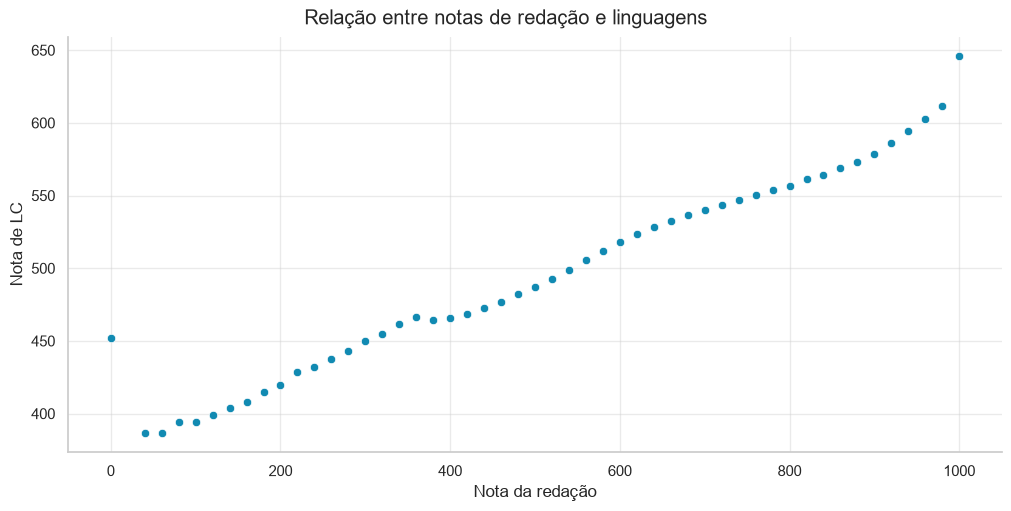

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt

# cria a moldura (fig) e o eixo do gráfico (ax)
fig, ax = plt.subplots(figsize=(10, 5), layout='constrained') # layout para considerar as bordas da figura ao alinhar o título
# Configurando o estilo do Seaborn
sns.set_theme(style="whitegrid")

# plotando o gráfico
ax = sns.scatterplot(
    data=df,
    x='REDACAO_NOTA',
    y='MEDIA_LC',
    color="#118AB2",
    ax=ax # especificar qual eixo deve ir esse gráfico (nesse caso só tem 1)
)

# títulos
fig.suptitle('Relação entre notas de redação e linguagens')
plt.xlabel('Nota da redação')
plt.ylabel('Nota de LC')

# controlar a transparência das barras do grid
ax.grid(alpha=0.4)

# remover as linhas superior e direita da caixa do gráfico.
sns.despine()

# Exportando o gráfico final em alta resolução
plt.savefig('../graficos/tendencia_redacao.png', dpi=300)

plt.show()


## Conclusões



Notamos pelo formato da distribuição, aproximadamente uma reta ascendente, que existe clara relação direta entre as notas de redação e as notas de LC. Conforme antecipamos na seção inicial dessa análise, essa relação já era esperada devido a complementaridade das competências avaliadas.

Os dois extremos do gráfico merecem uma atenção especial. No primeiro resultado vemos as redações de nota zero, mas que obtiveram um desempenho médio em LC considerável (equiparado ao desempenho médio de quem obteve 350 na redação). Notamos aqui que nem sempre as notas zero em redação são causadas por total desconhecimento da língua portuguesa. Caberia uma análise mais detalhada sobre as principais causas dessas notas zero em redação, mas essa análise está fora do escopo desse projeto.

Na outra ponta vemos as redações que receberam a nota máxima: mil pontos. A primeira vista, pela escala do gráfico, pode nos parecer que o máximo aproveitamento em redação se traduz num aproveitamente médio de apenas 65% em LC. Porém, devido à forma como o TRI funciona, nem sempre é possível obter nota 1000 nas áreas do conhecimento objetivas. Para entender melhor, vamos a uma breve análise das notas máximas de LC no perído considerado.

In [16]:
# abrir a conexão com banco de dados
con = duckdb.connect('../database/enem.duckdb')

# criar a consulta em SQL
query = """
    SELECT ANO AS Ano, MAX(NOTA_LC) AS "Nota máxima" FROM enem.main.silver_respostas GROUP BY ANO ORDER BY ANO
"""
# consultar a tabela e salvar em um dataframe
df_nota_maxima_lc = con.execute(query).df()

#Não esquecer de fechar a conexão
con.close()

# exibir o dataframe
df_nota_maxima_lc.head()

,Ano,Nota máxima
0,2021,826.099976
1,2022,801.000000
2,2023,820.799988
3,2024,795.799988
4,2025,794.500000


Conforme exposto acima entendemos que as notas máximas de LC se mantém por volta dos 807 pontos. Assim, uma nota média de 650 não está tão distante do máximo obtido, representando cerca de 80% da maior nota. Essa distância real nos mostra que os alunos que obtêm nota máxima em redação têm sim um desempenho ótimo também na prova de LC.